# 05 - Báo cáo so sánh mô hình QA trên DEV (giai đoạn 4)
UIT-ViQuAD 2.0, trích xuất câu trả lời. Notebook chỉ đọc **logits/summary đã lưu** trong `outputs/sweep/`, chạy hoàn toàn trên CPU.
Giai đoạn này chỉ dùng **dev**; test không được chấm (`RUN_TEST=False`).

## 1. Giao thức và tính công bằng
- Cùng chia dữ liệu train'/dev/test (`split_ids.json`) và cùng bộ metric `src/metrics.py`. Mọi lựa chọn (siêu tham số, biến thể hậu xử lý, ngưỡng) chỉ dựa trên **dev**; test chỉ chấm một lần ở cuối.
- **Nhóm A (so sánh công bằng)**: `xlmr_base`, `phobert`, `xlmr_large`. Cùng ngân sách tinh chỉnh, cùng số seed, huấn luyện **chỉ trên dữ liệu train của ViQuAD**.
- **Nhóm B (tham chiếu, không so sánh công bằng)**: `vi_mrc_base`, `vi_mrc_large` (nguyenvulebinh) được tiền huấn luyện/tinh chỉnh trên dữ liệu bổ sung, gồm cả VLSP-MRC-2021. ViQuAD 2.0 có thể trùng với dữ liệu này, nên điểm dev/ngưỡng của nhóm B có thể **lạc quan**. Ngoài ra ta suy luận theo đường subword của repo này, khác cách của tác giả (sum-features), nên điểm có thể lệch.
- Lưới hậu xử lý giống hệt nhau cho mọi mô hình.

In [1]:
import sys, logging
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from src import evalkit as ek
from src.postprocess import apply_threshold, tune_threshold
logging.basicConfig(level=logging.WARNING)
pd.set_option("display.width", 160)

RUN_TEST = False  # test scored once on 2026-11-13 (outputs below are from that run); do not re-run with True
N_BOOT = 2000      # 10000 cho báo cáo cuối
MODELS = ["xlmr_base", "phobert", "xlmr_large"]
if RUN_TEST:
    print("CẢNH BÁO: RUN_TEST=True, test sẽ được chấm.")
else:
    print("RUN_TEST=False: bỏ qua test (đặt True chỉ khi đã chốt cấu hình trên dev).")
STAGE_FINAL = "stage3"
GROUP_B = ["vi_mrc_base", "vi_mrc_large"]

CẢNH BÁO: RUN_TEST=True, test sẽ được chấm.


## 2. Tất cả các run (stage1 / stage2 / stage3 / zero-shot)

In [2]:
runs = ek.load_runs(ROOT / "outputs")
runs = runs[~runs.stage.str.contains("smoke")].reset_index(drop=True) if len(runs) else runs  # bỏ run smoke
if runs.empty:
    print("Chưa có run nào trong outputs/sweep/<stage>/<model>/<run_name>/ - các bảng bên dưới để trống.")
else:
    print(runs.groupby(["stage", "model"]).size().unstack(0).fillna(0).astype(int))
    cols = ["stage", "model", "run_name", "seed", "lr", "epochs", "lr_decay", "ema_decay", "plausible_lambda",
            "dev_f1", "dev_em", "dev_hasans_f1", "dev_noans_acc", "threshold"]
    display(runs[cols].sort_values(["stage", "model", "dev_f1"], ascending=[True, True, False]))

stage         stage1  stage2  stage3  zero_shot
model                                          
phobert            4       4       3          0
vi_mrc_base        0       0       0          1
vi_mrc_large       0       0       0          1
xlmr_base          4       4       3          0
xlmr_large         4       4       3          0


,stage,model,run_name,seed,lr,epochs,lr_decay,ema_decay,plausible_lambda,dev_f1,dev_em,dev_hasans_f1,dev_noans_acc,threshold
1,stage1,phobert,phobert__lr1.5e-5_e5,42.0,0.000015,5.0,NaN,NaN,0.0,68.319819,51.991758,72.853582,59.014675,-1.250000
0,stage1,phobert,phobert__base_lr2e-5_e3,42.0,0.000020,3.0,NaN,NaN,0.0,67.643716,52.300824,69.754087,63.312369,-1.500000
3,stage1,phobert,phobert__lr3e-5_e5_wu0.2,42.0,0.000030,5.0,NaN,NaN,0.0,67.383717,51.167582,73.248919,55.345912,0.082031
2,stage1,phobert,phobert__lr2e-5_e5,42.0,0.000020,5.0,NaN,NaN,0.0,66.489406,50.515110,72.072089,55.031447,-0.250000
5,stage1,xlmr_base,xlmr_base__lr2e-5_e5,42.0,0.000020,5.0,NaN,NaN,0.0,61.532663,48.111264,63.627739,57.232704,-0.500000
6,stage1,xlmr_base,xlmr_base__lr3e-5_e5,42.0,0.000030,5.0,NaN,NaN,0.0,61.380577,47.905220,64.678366,54.612159,-0.250000
4,stage1,xlmr_base,xlmr_base__base_lr3e-5_e3,42.0,0.000030,3.0,NaN,NaN,0.0,60.222560,46.050824,66.326912,47.693920,0.000000
7,stage1,xlmr_base,xlmr_base__lr5e-5_e4,42.0,0.000050,4.0,NaN,NaN,0.0,57.804046,45.020604,63.547181,46.016771,0.500000
8,stage1,xlmr_large,xlmr_large__base_lr1.5e-5_e3,42.0,0.000015,3.0,NaN,NaN,0.0,77.388933,62.671703,76.893041,78.406709,-1.750000
11,stage1,xlmr_large,xlmr_large__lr2e-5_e3,42.0,0.000020,3.0,NaN,NaN,0.0,77.250626,62.328297,76.227693,79.350105,-1.750000


## 3. Bảng bóc lớp (peeling layers) theo từng mô hình
Baseline -> +siêu tham số -> +LLRD -> +EMA -> +plausible loss (dev F1, trung bình theo seed; dùng run stage1+stage2).
**Nhận xét**: các phần thêm ở stage2 (LLRD, EMA, plausible loss) **không cải thiện ổn định**: mức chênh nhỏ, đổi dấu giữa các mô hình, thường nằm trong dao động giữa các seed. Công thức cuối vì thế chọn theo dev F1, không phải vì một add-on nào luôn có lợi.

In [3]:
early = runs[runs.stage.isin(["stage1", "stage2"])] if len(runs) else runs
for m in MODELS:
    print(m)
    display(ek.layer_table(early, m).round(2))

xlmr_base


,step,dev_f1,dev_em,n_seeds,delta_f1
0,baseline,60.22,46.05,1.0,NaN
1,+hyperparameters,61.53,48.11,1.0,1.31
2,+LLRD,59.85,45.67,1.0,-1.69


phobert


,step,dev_f1,dev_em,n_seeds,delta_f1
0,+hyperparameters,68.32,51.99,1.0,NaN
1,+LLRD,65.55,49.07,1.0,-2.77


xlmr_large


,step,dev_f1,dev_em,n_seeds,delta_f1
0,+hyperparameters,77.39,62.67,1.0,NaN
1,+LLRD,75.43,60.23,1.0,-1.96


## 4. Công thức cuối và bảng 3 seed trên dev (stage3)
Số liệu lấy thẳng từ `summary.json` (biến thể hậu xử lý mặc định `min/64/20`, ngưỡng tune trên dev). std là độ lệch chuẩn mẫu (ddof=1) qua 3 seed.

In [4]:
final = runs[runs.stage == STAGE_FINAL] if len(runs) else runs
rec = final.groupby("model")[["lr", "epochs", "train_bs", "lr_decay", "ema_decay", "plausible_lambda"]].first()
display(rec.reindex([m for m in MODELS if m in rec.index]))
met = ["dev_f1", "dev_em", "dev_hasans_f1", "dev_noans_acc"]
seed_tab = final.groupby("model")[met].agg(["mean", "std"]).reindex([m for m in MODELS if m in set(final.model)])
seed_tab.insert(0, "n_seeds", final.groupby("model").seed.nunique())
display(seed_tab.round(2))

,lr,epochs,train_bs,lr_decay,ema_decay,plausible_lambda
model,,,,,,
xlmr_base,0.000020,5.0,32.0,NaN,NaN,0.3
phobert,0.000015,5.0,32.0,NaN,NaN,0.0
xlmr_large,0.000015,3.0,16.0,NaN,NaN,0.3


C:\Users\PC\AppData\Local\Temp\ipykernel_7460\3747935289.py:6: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  seed_tab.insert(0, "n_seeds", final.groupby("model").seed.nunique())


n_seeds dev_f1       dev_em       dev_hasans_f1       dev_noans_acc      
                     mean   std   mean   std          mean   std          mean   std
model                                                                               
xlmr_base        3  61.68  1.77  47.15  1.62         66.83  2.54         51.12  5.71
phobert          3  67.72  1.10  52.35  1.17         68.61  0.32         65.90  3.72
xlmr_large       3  77.20  0.32  62.24  0.24         77.34  1.63         76.90  2.48

## 5. Lưới hậu xử lý trên dev (ensemble 3 seed của stage3)
Lưới: null_variant {min, mean, first} x max_answer_length {30, 64, 96} x n_best {20, 50} (18 biến thể, giống nhau cho mọi mô hình). Chọn theo F1 dev ở ngưỡng đã tune; nếu chênh <= 0.3 so với mặc định (min, 64, 20) thì giữ mặc định.
Biến thể và ngưỡng được tune trên chính dev nên số này hơi lạc quan.

In [5]:
choices, ctx, ens, grids, fruns = {}, {}, {}, {}, {}
for m in MODELS:
    sub = final[final.model == m] if len(final) else final
    if sub.empty:
        print(m, ": không có run stage3, bỏ qua"); continue
    fruns[m] = [ek.load_run(d) for d in sub.sort_values("seed").run_dir]
    ex, feats, extract = ek.build_eval_context(m, "dev", expected_hash=fruns[m][0]["dev"]["feature_hash"])
    ctx[m] = (ex, feats, extract)
    s, e, _, _ = ek.ensemble_logits(fruns[m])
    ens[m] = (s, e)
    choices[m], grids[m] = ek.tune_variant_grid(ex, feats, s, e, extract)
    print(m, f"({len(fruns[m])} seed ensemble)", choices[m])
    display(grids[m].sort_values("f1", ascending=False).head(6).round(2))
if choices:
    display(pd.DataFrame(choices).T.round(2))

D:\00_Workspace\AI_Lab\RAG_official\Extractive_QA\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


xlmr_base (3 seed ensemble) {'null_variant': 'min', 'max_answer_length': 64, 'n_best': 20, 'threshold': 0.5, 'f1': 62.867462927341066}


,null_variant,max_answer_length,n_best,threshold,f1,em,HasAns_f1,NoAns_acc
10,mean,96,20,0.5,63.01,49.21,66.54,55.77
11,mean,96,50,0.5,63.01,49.21,66.54,55.77
17,first,96,50,0.5,62.98,49.18,66.49,55.77
16,first,96,20,0.5,62.98,49.18,66.49,55.77
5,min,96,50,0.5,62.98,49.18,66.59,55.56
4,min,96,20,0.5,62.98,49.18,66.59,55.56


Casting the dataset:   0%|          | 0/25533 [00:00<?, ? examples/s]

Casting the dataset: 100%|██████████| 25533/25533 [00:00<00:00, 913857.77 examples/s]

Casting the dataset:   0%|          | 0/2912 [00:00<?, ? examples/s]

... (9 outputs left out)

,null_variant,max_answer_length,n_best,threshold,f1,em,HasAns_f1,NoAns_acc
9,mean,64,50,-1.50,68.77,52.88,72.14,61.84
8,mean,64,20,-1.50,68.77,52.88,72.14,61.84
11,mean,96,50,-1.50,68.76,52.85,72.13,61.84
10,mean,96,20,-1.50,68.76,52.85,72.13,61.84
2,min,64,20,-1.69,68.75,52.99,71.61,62.89
3,min,64,50,-1.69,68.75,52.99,71.61,62.89


xlmr_large (3 seed ensemble) {'null_variant': 'min', 'max_answer_length': 64, 'n_best': 20, 'threshold': 0.2820313215255695, 'f1': 78.85710829929288}


,null_variant,max_answer_length,n_best,threshold,f1,em,HasAns_f1,NoAns_acc
3,min,64,50,0.28,78.86,63.43,79.79,76.94
2,min,64,20,0.28,78.86,63.43,79.79,76.94
14,first,64,20,0.28,78.86,63.43,79.79,76.94
15,first,64,50,0.28,78.86,63.43,79.79,76.94
8,mean,64,20,0.25,78.81,63.43,79.67,77.04
9,mean,64,50,0.25,78.81,63.43,79.67,77.04


,null_variant,max_answer_length,n_best,threshold,f1
xlmr_base,min,64,20,0.5,62.867463
phobert,min,64,20,-1.694271,68.754073
xlmr_large,min,64,20,0.282031,78.857108


## 6. Ensemble seed so với từng seed riêng lẻ (dev)
Mọi dòng dùng cùng biến thể hậu xử lý đã chọn ở mục 5, ngưỡng tune lại riêng cho từng seed / cho ensemble.

In [6]:
def dev_eval(m, s, e, c):
    ex, feats, extract = ctx[m]
    sc = ek.rescore(ex, feats, s, e, extract, c["null_variant"], c["max_answer_length"], c["n_best"])
    refs = ek.refs_of(ex)
    t, _ = tune_threshold(sc, refs)
    return sc, t, ek.per_example(apply_threshold(sc, t), refs)

pe_dev, rows = {}, []
thr_ens, thr_seed, thr_b = {}, {}, {}  # ngưỡng dev, dùng lại khi chấm test
for m in choices:
    c = choices[m]
    sv = [dev_eval(m, r["dev"]["start"], r["dev"]["end"], c) for r in fruns[m]]
    singles = [x[2].f1.mean() * 100 for x in sv]
    thr_seed[m] = [x[1] for x in sv]
    _, t, pe = dev_eval(m, *ens[m], c)
    thr_ens[m] = t
    pe_dev[m] = pe
    ef1 = pe.f1.mean() * 100
    rows.append({"model": m, "variant": (c["null_variant"], c["max_answer_length"], c["n_best"]),
                 "seeds_f1": [round(x, 2) for x in singles], "seed_mean": np.mean(singles),
                 "seed_std": np.std(singles, ddof=1) if len(singles) > 1 else np.nan,
                 "ensemble_f1": ef1, "gain_vs_mean": ef1 - np.mean(singles), "ens_em": pe.em.mean() * 100,
                 "ens_hasans_f1": pe[pe.has_ans].f1.mean() * 100, "ens_noans_acc": pe[~pe.has_ans].em.mean() * 100})
ens_tab = pd.DataFrame(rows).set_index("model")
display(ens_tab.round(2))

,variant,seeds_f1,seed_mean,seed_std,ensemble_f1,gain_vs_mean,ens_em,ens_hasans_f1,ens_noans_acc
model,,,,,,,,,
xlmr_base,"(min, 64, 20)","[62.29, 63.07, 59.69]",61.68,1.77,62.87,1.19,49.04,66.33,55.77
phobert,"(min, 64, 20)","[68.31, 66.45, 68.41]",67.72,1.10,68.75,1.03,52.99,71.61,62.89
xlmr_large,"(min, 64, 20)","[76.9, 77.12, 77.59]",77.20,0.35,78.86,1.65,63.43,79.79,76.94


## 7. Nhóm B: tham chiếu `vi_mrc_*` (zero-shot) trên dev
Chỉ chạy nếu có run trong `outputs/sweep/zero_shot/`. Dùng biến thể mặc định (min/64/20), ngưỡng tune trên dev.
**Lưu ý**: các mô hình này đã thấy dữ liệu bổ sung (VLSP-MRC-2021, có thể trùng ViQuAD 2.0) nên dev **lạc quan**, và đường suy luận subword khác tác giả. Đây là mốc tham chiếu, không phải đối thủ công bằng của nhóm A.

In [7]:
zs_rows = []
for m in GROUP_B:
    sub = runs[(runs.model == m) & (runs.stage == "zero_shot")] if len(runs) else runs
    if sub.empty:
        print(m, ": chưa có run zero-shot (chạy `python -m src.zero_shot --model all`), bỏ qua"); continue
    r = ek.load_run(sub.iloc[0].run_dir)
    ex, feats, extract = ek.build_eval_context(m, "dev", expected_hash=r["dev"]["feature_hash"])
    ctx[m] = (ex, feats, extract)
    c = dict(zip(("null_variant", "max_answer_length", "n_best"), ek.DEFAULT_VARIANT))
    _, t, pe = dev_eval(m, r["dev"]["start"], r["dev"]["end"], c)
    pe_dev[m] = pe
    thr_b[m] = t
    zs_rows.append({"model": m, "threshold": t, "f1": pe.f1.mean() * 100, "em": pe.em.mean() * 100,
                    "hasans_f1": pe[pe.has_ans].f1.mean() * 100, "noans_acc": pe[~pe.has_ans].em.mean() * 100})
if zs_rows:
    zs_tab = pd.DataFrame(zs_rows).set_index("model")
    display(zs_tab.round(2))

,threshold,f1,em,hasans_f1,noans_acc
model,,,,,
vi_mrc_base,-9.50,64.45,52.58,79.04,34.49
vi_mrc_large,-9.25,89.74,80.29,86.27,96.86


## 8. Khoảng tin cậy bootstrap 95% trên dev
Bootstrap theo ví dụ (ensemble nhóm A, và nhóm B nếu có). CI chỉ phản ánh phương sai do mẫu ví dụ, không phải phương sai huấn luyện.

In [8]:
import itertools
if pe_dev:
    ci_dev = pd.concat({m: ek.ci_table(p, N_BOOT) for m, p in pe_dev.items()})
    display(ci_dev.round(2))
    f = ci_dev[(ci_dev.subset == "overall") & (ci_dev.metric == "f1")].reset_index(level=0)
    fig, ax = plt.subplots(figsize=(6, 3))
    ax.errorbar(f["mean"], range(len(f)), xerr=[f["mean"] - f["lo"], f["hi"] - f["mean"]], fmt="o")
    ax.set_yticks(range(len(f))); ax.set_yticklabels(f["level_0"]); ax.set_xlabel("dev F1 (95% CI)")
    plt.tight_layout(); plt.show()
    rows = []
    for a, b in itertools.combinations([m for m in MODELS if m in pe_dev], 2):
        r = ek.paired_bootstrap(pe_dev[a].f1.values * 100, pe_dev[b].f1.values * 100, N_BOOT)
        rows.append({"A": a, "B": b, "metric": "f1", **r})
    if rows:
        print("Kiểm định ghép cặp trên dev (p = tỉ lệ resample có hiệu A-B <= 0):")
        display(pd.DataFrame(rows).round(4))
else:
    print("Chưa có điểm dev.")

subset metric     n   mean     lo     hi
xlmr_base    0  overall     em  2912  49.04  47.15  50.86
             1  overall     f1  2912  62.87  61.19  64.38
             2   HasAns     em  1958  45.76  43.61  48.01
             3   HasAns     f1  1958  66.33  64.57  68.11
             4    NoAns     em   954  55.77  52.62  58.91
             5    NoAns     f1   954  55.77  52.62  58.91
phobert      0  overall     em  2912  52.99  51.06  54.88
             1  overall     f1  2912  68.75  67.20  70.29
             2   HasAns     em  1958  48.16  45.97  50.46
             3   HasAns     f1  1958  71.61  69.90  73.30
             4    NoAns     em   954  62.89  59.85  66.04
             5    NoAns     f1   954  62.89  59.85  66.04
xlmr_large   0  overall     em  2912  63.43  61.68  65.21
             1  overall     f1  2912  78.86  77.50  80.17
             2   HasAns     em  1958  56.84  54.65  59.09
             3   HasAns     f1  1958  79.79  78.32  81.21
             4    NoAns     em   954  76.94  74.21  79.56
             5    NoAns     f1   954  76.94  74.21  79.56
vi_mrc_base  0  overall     em  2912  52.58  50.75  54.46
             1  overall     f1  2912  64.45  62.76  66.10
             2   HasAns     em  1958  61.39  59.24  63.54
             3   HasAns     f1  1958  79.04  77.49  80.63
             4    NoAns     em   954  34.49  31.45  37.53
             5    NoAns     f1   954  34.49  31.45  37.53
vi_mrc_large 0  overall     em  2912  80.29  78.85  81.73
             1  overall     f1  2912  89.74  88.75  90.72
             2   HasAns     em  1958  72.22  70.28  74.21
             3   HasAns     f1  1958  86.27  85.04  87.60
             4    NoAns     em   954  96.86  95.70  97.90
             5    NoAns     f1   954  96.86  95.70  97.90

Kiểm định ghép cặp trên dev (p = tỉ lệ resample có hiệu A-B <= 0):


C:\Users\PC\AppData\Local\Temp\ipykernel_7460\3503968644.py:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.show()


,A,B,metric,diff,lo,hi,p
0,xlmr_base,phobert,f1,-5.8866,-7.4704,-4.3622,1.0
1,xlmr_base,xlmr_large,f1,-15.9896,-17.6355,-14.3866,1.0
2,phobert,xlmr_large,f1,-10.1030,-11.7110,-8.5822,1.0


## 9. Giao thức đã chốt và bảng test (đóng, chỉ dùng sau khi chốt cấu hình)
**Quyết định đã đóng băng (chốt trên dev, không đổi sau khi thấy test):**
- Công thức cuối mỗi mô hình nhóm A: run `stage3` (`final_s42/43/44`) với siêu tham số ở bảng mục 4.
- Ensemble = trung bình logits của **3 seed** (42, 43, 44).
- Biến thể hậu xử lý: `min` / `max_answer_length=64` / `n_best=20` (kết quả lưới dev ở mục 5).
- Ngưỡng no-answer tune trên **dev** cho đúng cấu hình đó (ensemble dùng ngưỡng của ensemble; từng seed dùng ngưỡng dev của riêng seed), không tune lại trên test.
- Nhóm A: chấm test (a) ensemble 3 seed, (b) từng seed riêng (báo cáo mean±std). Nhóm B (`vi_mrc_base`, `vi_mrc_large`): một run, biến thể mặc định, ngưỡng dev.
- Test được chấm **một lần** trong ô kế tiếp, chỉ khi `RUN_TEST=True`. **Không bật ở giai đoạn dev.**

In [9]:
# tự kiểm tra: RUN_TEST là bool và ngưỡng dev đã nạp trước khi chấm test
assert isinstance(RUN_TEST, bool), "RUN_TEST phải là bool"
assert all(k in globals() for k in ("thr_ens", "thr_seed", "thr_b", "choices", "fruns")), "chạy các ô dev trước"
if RUN_TEST:
    assert all(m in thr_ens and len(thr_seed[m]) == len(fruns[m]) == 3 for m in MODELS), "thiếu ngưỡng dev nhóm A"
    assert all(m in thr_b for m in GROUP_B), "thiếu ngưỡng dev nhóm B"
import contextlib, io

pe_test, pe_test_seeds, test_thr = {}, {}, {}
if not RUN_TEST:
    print("RUN_TEST=False: không chấm test.")
else:
    buf = io.StringIO()
    prev = logging.root.manager.disable
    logging.disable(logging.WARNING)
    try:
        with contextlib.redirect_stdout(buf):  # evalkit in cảnh báo ở mỗi lần nạp; in gộp một lần bên dưới
            def score_test(s, e, c, thr, ex, feats, extract):
                sc = ek.rescore(ex, feats, s, e, extract, c["null_variant"], c["max_answer_length"], c["n_best"])
                return ek.per_example(apply_threshold(sc, thr), ek.refs_of(ex))
            for m in MODELS:
                c = choices[m]
                rs = [ek.load_run(r["run_dir"], allow_test=True) for r in fruns[m]]
                ex, feats, extract = ek.build_eval_context(m, "test", allow_test=True, expected_hash=rs[0]["test"]["feature_hash"])
                s, e, _, _ = ek.ensemble_logits(rs, split="test", allow_test=True)
                pe_test[m] = score_test(s, e, c, thr_ens[m], ex, feats, extract); test_thr[m] = thr_ens[m]
                pe_test_seeds[m] = [score_test(r["test"]["start"], r["test"]["end"], c, t, ex, feats, extract)
                                    for r, t in zip(rs, thr_seed[m])]
            for m in GROUP_B:
                sub = runs[(runs.model == m) & (runs.stage == "zero_shot")]
                r = ek.load_run(sub.iloc[0].run_dir, allow_test=True)
                ex, feats, extract = ek.build_eval_context(m, "test", allow_test=True, expected_hash=r["test"]["feature_hash"])
                c = dict(zip(("null_variant", "max_answer_length", "n_best"), ek.DEFAULT_VARIANT))
                pe_test[m] = score_test(r["test"]["start"], r["test"]["end"], c, thr_b[m], ex, feats, extract); test_thr[m] = thr_b[m]
    finally:
        logging.disable(prev)
    print("WARNING: TEST SPLIT SCORED")
    for m in MODELS:
        f = [p.f1.mean() * 100 for p in pe_test_seeds[m]]
        print(f"{m}: ensemble F1 {pe_test[m].f1.mean()*100:.2f} | seeds F1 {np.mean(f):.2f} ± {np.std(f, ddof=1):.2f}")
    for m in GROUP_B:
        print(f"{m}: F1 {pe_test[m].f1.mean()*100:.2f}")

Map:   0%|          | 0/3814 [00:00<?, ? examples/s]

Map:  26%|██▌       | 1000/3814 [00:00<00:00, 3899.76 examples/s]

Map:  52%|█████▏    | 2000/3814 [00:00<00:00, 4490.86 examples/s]

Map:  79%|███████▊  | 3000/3814 [00:00<00:00, 4620.64 examples/s]

Map: 100%|██████████| 3814/3814 [00:00<00:00, 4765.26 examples/s]

Map: 100%|██████████| 3814/3814 [00:00<00:00, 4449.79 examples/s]

... (27 outputs left out)

Map:  79%|███████▊  | 3000/3814 [00:00<00:00, 4616.29 examples/s]

Map: 100%|██████████| 3814/3814 [00:00<00:00, 4700.00 examples/s]

Map: 100%|██████████| 3814/3814 [00:00<00:00, 4398.20 examples/s]

xlmr_base: ensemble F1 62.40 | seeds F1 61.95 ± 1.25
phobert: ensemble F1 68.97 | seeds F1 67.38 ± 0.78
xlmr_large: ensemble F1 77.89 | seeds F1 76.40 ± 1.25
vi_mrc_base: F1 64.72
vi_mrc_large: F1 80.48


## 10. Bảng test với khoảng tin cậy bootstrap 95%
Bảng EM, F1, HasAns F1, NoAns acc (CI bootstrap theo ví dụ). Nhóm A = ensemble 3 seed; `vi_mrc_*` là tham chiếu (không so sánh công bằng).

In [10]:
if pe_test:
    ci = pd.concat({m: ek.ci_table(p, N_BOOT) for m, p in pe_test.items()})
    display(ci.round(2))
    lab = {("overall", "em"): "EM", ("overall", "f1"): "F1", ("HasAns", "f1"): "HasAns F1", ("NoAns", "em"): "NoAns acc"}
    t = ci.reset_index(level=0).rename(columns={"level_0": "model"})
    t["k"] = [lab.get((a, b)) for a, b in zip(t.subset, t.metric)]
    t = t.dropna(subset=["k"])
    t["val"] = t.apply(lambda r: f"{r['mean']:.2f} [{r['lo']:.2f}, {r['hi']:.2f}]", axis=1)
    display(t.pivot(index="model", columns="k", values="val")[["EM", "F1", "HasAns F1", "NoAns acc"]])
    sd = pd.DataFrame({m: {"seed_F1_mean": np.mean([p.f1.mean() * 100 for p in ps]),
                           "seed_F1_std": np.std([p.f1.mean() * 100 for p in ps], ddof=1),
                           "seed_EM_mean": np.mean([p.em.mean() * 100 for p in ps]),
                           "seed_EM_std": np.std([p.em.mean() * 100 for p in ps], ddof=1)}
                       for m, ps in pe_test_seeds.items()}).T
    print("Từng seed riêng (ngưỡng dev của seed), mean ± std qua 3 seed:")
    display(sd.round(2))
else:
    print("Chưa có điểm test; bảng và CI sẽ tính khi RUN_TEST=True.")

subset metric     n   mean     lo     hi
xlmr_base    0  overall     em  3814  53.99  52.31  55.56
             1  overall     f1  3814  62.40  60.89  63.78
             2   HasAns     em  2653  52.05  50.09  53.90
             3   HasAns     f1  2653  64.15  62.48  65.73
             4    NoAns     em  1161  58.40  55.64  60.98
             5    NoAns     f1  1161  58.40  55.64  60.98
phobert      0  overall     em  3814  59.49  57.94  61.01
             1  overall     f1  3814  68.97  67.63  70.33
             2   HasAns     em  2653  57.56  55.75  59.44
             3   HasAns     f1  2653  71.18  69.68  72.72
             4    NoAns     em  1161  63.91  61.15  66.58
             5    NoAns     f1  1161  63.91  61.15  66.58
xlmr_large   0  overall     em  3814  68.35  66.91  69.90
             1  overall     f1  3814  77.89  76.68  79.15
             2   HasAns     em  2653  64.68  62.87  66.53
             3   HasAns     f1  2653  78.39  77.01  79.74
             4    NoAns     em  1161  76.74  74.33  79.16
             5    NoAns     f1  1161  76.74  74.33  79.16
vi_mrc_base  0  overall     em  3814  57.26  55.69  58.86
             1  overall     f1  3814  64.72  63.25  66.18
             2   HasAns     em  2653  66.72  64.87  68.41
             3   HasAns     f1  2653  77.43  75.93  78.87
             4    NoAns     em  1161  35.66  32.99  38.42
             5    NoAns     f1  1161  35.66  32.99  38.42
vi_mrc_large 0  overall     em  3814  68.90  67.46  70.35
             1  overall     f1  3814  80.48  79.33  81.63
             2   HasAns     em  2653  69.81  68.04  71.43
             3   HasAns     f1  2653  86.45  85.40  87.49
             4    NoAns     em  1161  66.84  64.17  69.60
             5    NoAns     f1  1161  66.84  64.17  69.60

k,EM,F1,HasAns F1,NoAns acc
model,,,,
phobert,"59.49 [57.94, 61.01]","68.97 [67.63, 70.33]","71.18 [69.68, 72.72]","63.91 [61.15, 66.58]"
vi_mrc_base,"57.26 [55.69, 58.86]","64.72 [63.25, 66.18]","77.43 [75.93, 78.87]","35.66 [32.99, 38.42]"
vi_mrc_large,"68.90 [67.46, 70.35]","80.48 [79.33, 81.63]","86.45 [85.40, 87.49]","66.84 [64.17, 69.60]"
xlmr_base,"53.99 [52.31, 55.56]","62.40 [60.89, 63.78]","64.15 [62.48, 65.73]","58.40 [55.64, 60.98]"
xlmr_large,"68.35 [66.91, 69.90]","77.89 [76.68, 79.15]","78.39 [77.01, 79.74]","76.74 [74.33, 79.16]"


Từng seed riêng (ngưỡng dev của seed), mean ± std qua 3 seed:


,seed_F1_mean,seed_F1_std,seed_EM_mean,seed_EM_std
xlmr_base,61.95,1.25,52.81,1.01
phobert,67.38,0.78,57.94,0.37
xlmr_large,76.40,1.25,66.61,0.93


In [11]:
REF = "vi_mrc_large"  # tham chiếu (nhóm B), không phải đối thủ công bằng
if len(pe_test) >= 2:
    rows = []
    pairs = list(itertools.combinations([m for m in MODELS if m in pe_test], 2))
    pairs += [(m, REF) for m in MODELS if m in pe_test and REF in pe_test]
    for a, b in pairs:
        for met in ("f1", "em"):
            r = ek.paired_bootstrap(pe_test[a][met].values * 100, pe_test[b][met].values * 100, N_BOOT)
            rows.append({"A": a, "B": b + (" (tham chiếu)" if b == REF else ""), "metric": met, **r})
    print("Kiểm định ghép cặp trên test (p = tỉ lệ resample có hiệu A-B <= 0):")
    display(pd.DataFrame(rows).round(4))
else:
    print("Cần >= 2 mô hình có điểm test.")

Kiểm định ghép cặp trên test (p = tỉ lệ resample có hiệu A-B <= 0):


,A,B,metric,diff,lo,hi,p
0,xlmr_base,phobert,f1,-6.5717,-7.9747,-5.1593,1.0000
1,xlmr_base,phobert,em,-5.5060,-7.0530,-4.0378,1.0000
2,xlmr_base,xlmr_large,f1,-15.4932,-16.9924,-13.9998,1.0000
3,xlmr_base,xlmr_large,em,-14.3681,-15.9419,-12.8212,1.0000
4,phobert,xlmr_large,f1,-8.9215,-10.2529,-7.5738,1.0000
5,phobert,xlmr_large,em,-8.8621,-10.3835,-7.3676,1.0000
6,xlmr_base,vi_mrc_large (tham chiếu),f1,-18.0845,-19.8180,-16.3464,1.0000
7,xlmr_base,vi_mrc_large (tham chiếu),em,-14.9187,-16.9638,-12.8998,1.0000
8,phobert,vi_mrc_large (tham chiếu),f1,-11.5128,-13.1577,-9.8456,1.0000
9,phobert,vi_mrc_large (tham chiếu),em,-9.4127,-11.4578,-7.3932,1.0000


## 10b. Chênh lệch dev so với test
Nhóm A: ensemble 3 seed. Dev của `vi_mrc_*` có thể lạc quan (khả năng trùng dữ liệu VLSP-MRC-2021), nên chênh lệch dev-test lớn ở nhóm B là dấu hiệu cần cảnh giác.

In [12]:
if pe_test:
    g = []
    for m, pt in pe_test.items():
        pd_ = pe_dev[m]
        g.append({"model": m, "dev_f1": pd_.f1.mean() * 100, "test_f1": pt.f1.mean() * 100,
                  "dev_em": pd_.em.mean() * 100, "test_em": pt.em.mean() * 100})
    g = pd.DataFrame(g).set_index("model")
    g["gap_f1(dev-test)"] = g.dev_f1 - g.test_f1
    g["gap_em(dev-test)"] = g.dev_em - g.test_em
    display(g.round(2))
else:
    print("Chưa có điểm test; bảng chênh lệch dev-test sẽ tính khi RUN_TEST=True.")

,dev_f1,test_f1,dev_em,test_em,gap_f1(dev-test),gap_em(dev-test)
model,,,,,,
xlmr_base,62.87,62.40,49.04,53.99,0.47,-4.95
phobert,68.75,68.97,52.99,59.49,-0.21,-6.50
xlmr_large,78.86,77.89,63.43,68.35,0.97,-4.93
vi_mrc_base,64.45,64.72,52.58,57.26,-0.27,-4.69
vi_mrc_large,89.74,80.48,80.29,68.90,9.26,11.38


## 11. Bảng chi phí

In [13]:
display(ek.cost_table(runs))

,model,params_M,n_runs,train_runtime_s,est_units,windows_per_s
0,phobert,135.0,11,291.349827,NaN,483.063525
1,vi_mrc_base,277.5,1,NaN,NaN,NaN
2,vi_mrc_large,559.9,1,NaN,NaN,NaN
3,xlmr_base,277.5,11,413.635436,NaN,312.469065
4,xlmr_large,559.9,11,851.424500,NaN,104.978952


## 12. Hạn chế
- Số seed ít (3) nên std qua seed rất thô; CI bootstrap chỉ phản ánh phương sai mẫu ví dụ.
- Biến thể hậu xử lý và ngưỡng đều chọn trên dev, nên điểm dev hơi lạc quan; số công bố phải lấy từ test.
- Nhóm B có thể đã thấy dữ liệu trùng dev (VLSP-MRC-2021), nên không so sánh công bằng với nhóm A.
- Logits lưu ở float16; chấm lại có thể lệch rất nhỏ so với điểm lúc huấn luyện.
- Số tham số trong bảng chi phí là xấp xỉ; `est_units` chỉ có nếu run ghi lại.

## Biểu đồ tổng hợp (ảnh tĩnh)
Các hình dưới đây là ảnh tĩnh, sinh bởi `python docs/make_figures.py` từ các số liệu được phân tích (parse) trực tiếp từ output đã lưu của notebook này (các cell phía trên) và các file kết quả. Ảnh được nhúng vào output đã lưu mà không chạy lại notebook, vì việc chấm điểm test chỉ được thực hiện một lần. Để sinh lại hình, chạy lại script trên.

**`fig04_test_f1_ci.png`**: F1 test của từng mô hình kèm khoảng tin cậy bootstrap 95%.
Nguồn số liệu trong notebook này: cell 19 (bảng test với CI) và cell 20.

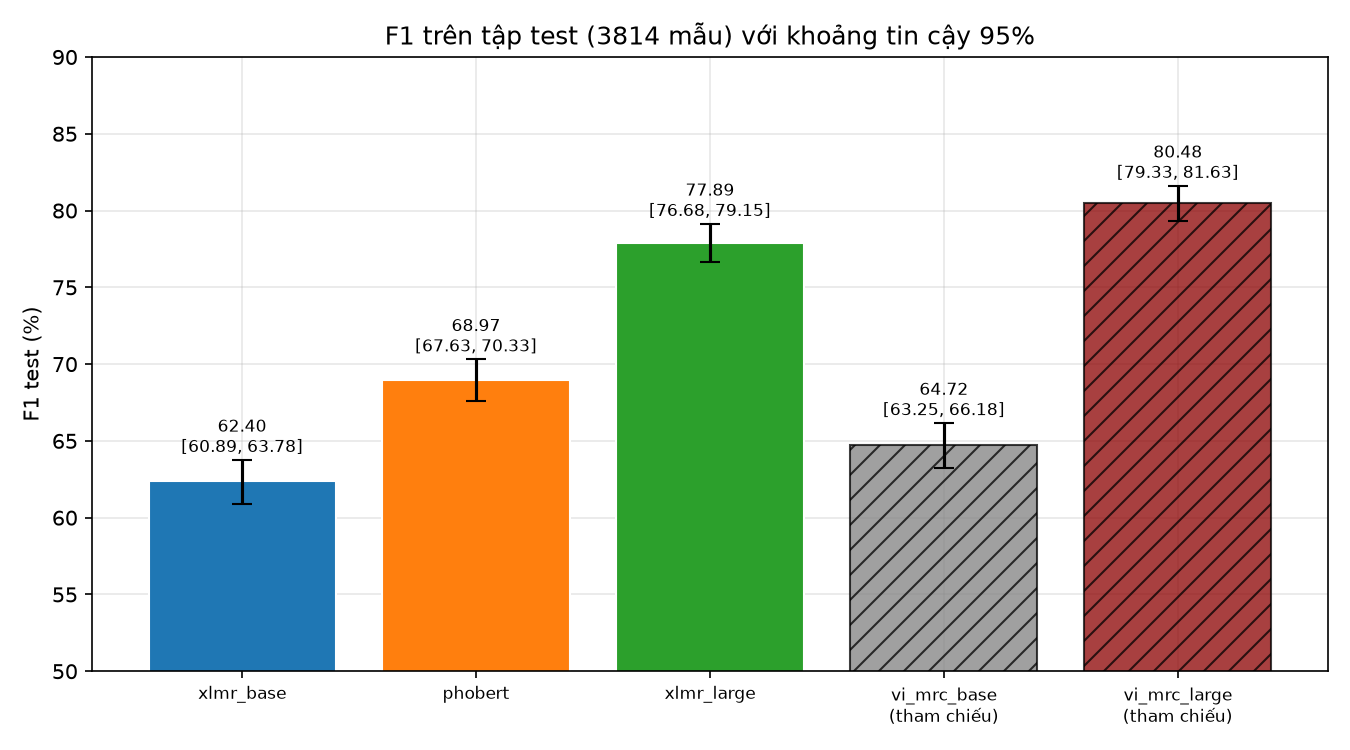

In [ ]:
from IPython.display import Image, display
display(Image(filename=ROOT / 'docs' / 'figures' / 'fig04_test_f1_ci.png'))

**`fig05_dev_vs_test.png`**: So sánh F1 dev với F1 test của từng mô hình (chênh lệch dev so với test).
Nguồn số liệu trong notebook này: cell 15 (CI dev) và cell 22 (chênh lệch dev/test).

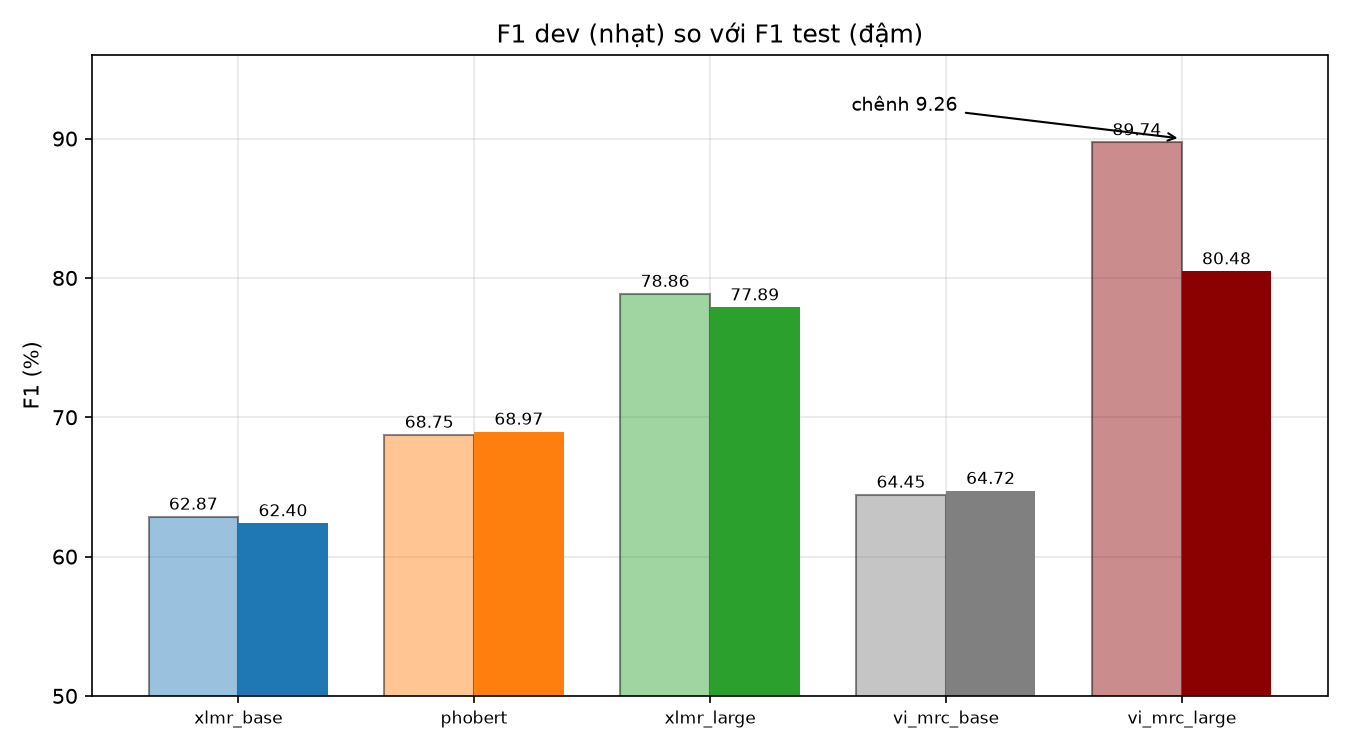

In [ ]:
from IPython.display import Image, display
display(Image(filename=ROOT / 'docs' / 'figures' / 'fig05_dev_vs_test.png'))

**`fig06_hasans_vs_noans.png`**: Điểm HasAns F1 và NoAns EM trên test của từng mô hình.
Nguồn số liệu trong notebook này: cell 19 (bảng test với CI).

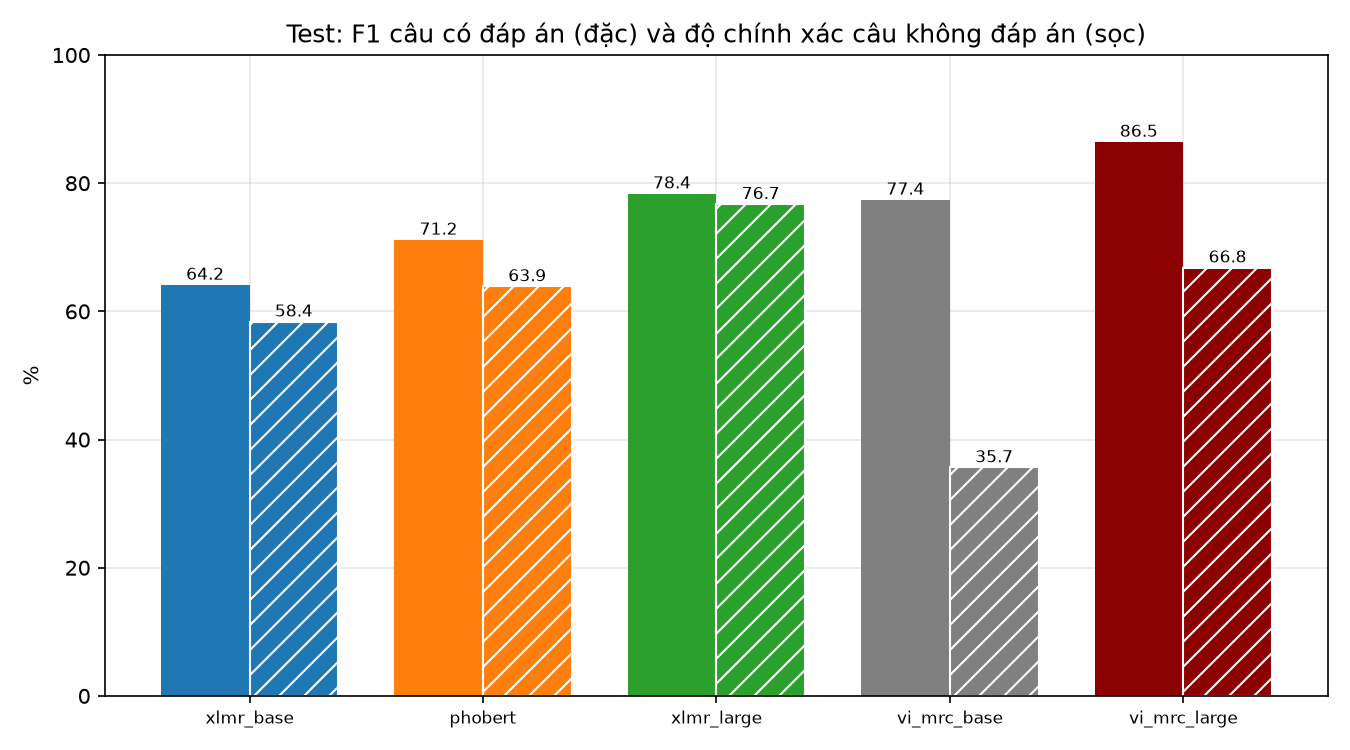

In [ ]:
from IPython.display import Image, display
display(Image(filename=ROOT / 'docs' / 'figures' / 'fig06_hasans_vs_noans.png'))

**`fig03_seeds_dev.png`**: F1 dev theo từng seed và ensemble 3 seed của giai đoạn 3.
Nguồn số liệu trong notebook này: cell 7 (bảng 3 seed) và cell 11 (ensemble so với từng seed).

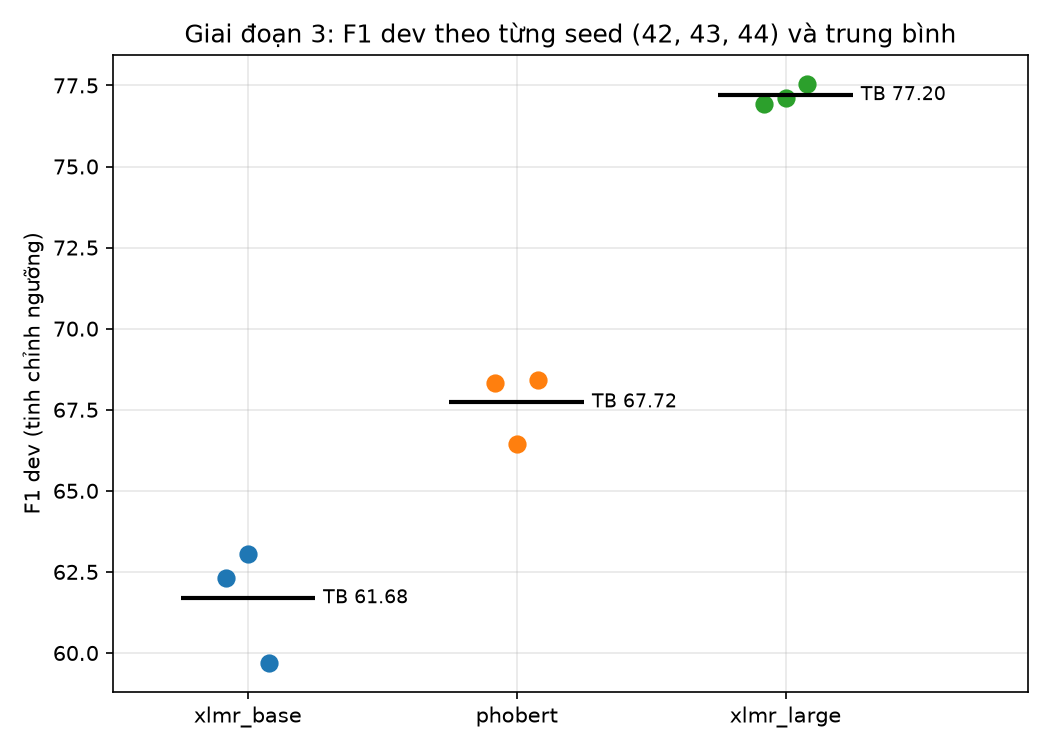

In [ ]:
from IPython.display import Image, display
display(Image(filename=ROOT / 'docs' / 'figures' / 'fig03_seeds_dev.png'))

**`fig08_cost_vs_f1.png`**: Chi phí (số tham số, đơn vị tính toán ước lượng) so với F1.
Nguồn số liệu trong notebook này: cell 24 (bảng chi phí) và cell 19.

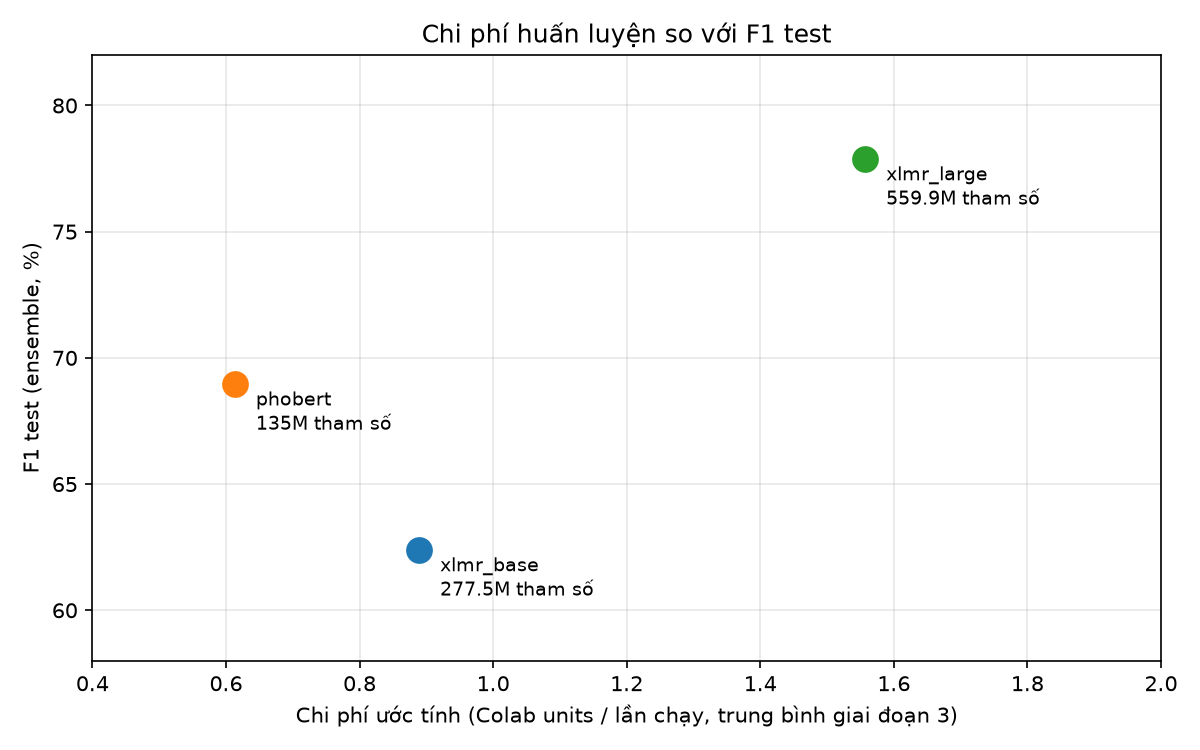

In [ ]:
from IPython.display import Image, display
display(Image(filename=ROOT / 'docs' / 'figures' / 'fig08_cost_vs_f1.png'))